![trader](trader.jpg)


A alocação de ativos é a decisão mais importante que qualquer investidor precisa tomar. É preciso decidir como distribuir o capital total entre determinados ativos (neste caso, ações). Ao considerar a alocação, o investidor quer equilibrar o risco e o potencial de retorno. Ao mesmo tempo, a alocação depende de fatores como objetivos individuais, tolerância ao risco e horizonte de investimento.

O principal referencial usado na alocação de ativos é a Modern Portfolio Theory (MPT), apresentada pelo ganhador do Prêmio Nobel Harry Markowitz. A MPT descreve como investidores podem construir portfólios para maximizar os retornos esperados para um determinado nível de risco ou, inversamente, minimizar o risco para um dado nível de retorno esperado. A base matemática usada para isso é chamada de otimização média-variância.

O principal insight da MPT é que os investidores não devem avaliar o desempenho de um ativo isoladamente. Em vez disso, devem avaliar como ele impacta o desempenho de um portfólio de ativos. Outro ponto importante é o conceito de diversificação, que significa que possuir diferentes tipos de ativos reduz o risco. Isso acontece porque a perda ou o ganho de um papel específico tem menos impacto no desempenho geral do portfólio.

**Sua tarefa**

No dinâmico mundo das finanças, cientistas/analistas de dados costumam ser responsáveis por encontrar estratégias de investimento ideais. Imagine que você é uma dessas pessoas e recebeu a missão de montar um portfólio eficiente com ações FAANG – Facebook (Meta), Apple, Amazon, Netflix e Google. Seu objetivo é maximizar os retornos enquanto reduz o risco.

Neste projeto, sua tarefa é encontrar a alocação ideal entre as ações FAANG com base em dados históricos de preços no período de 2020 a 2023. O conjunto de dados está no arquivo `faang_stocks.csv`. Para cada dia de negociação, ele contém os preços de fechamento das cinco empresas de tecnologia.


In [1]:
# Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pypfopt.efficient_frontier import EfficientFrontier
from pypfopt import risk_models
from pypfopt import expected_returns

# Setting the plotting style to be colorblind-friendly
# Setting the plotting style to be colorblind-friendly (compatible with modern matplotlib >= 3.8 and legacy versions)
if "seaborn-v0_8-colorblind" in plt.style.available:
    plt.style.use("seaborn-v0_8-colorblind")
elif "seaborn-colorblind" in plt.style.available:
    plt.style.use("seaborn-colorblind")
else:
    plt.style.use("tableau-colorblind10")


# Loading data
stock_prices_df = pd.read_csv("faang_stocks.csv", index_col="Date")

# Changing the index to a datetime type allows for easier filtering and plotting.
stock_prices_df.index = pd.to_datetime(stock_prices_df.index)
stock_prices_df


,AAPL,AMZN,GOOGL,META,NFLX
Date,,,,,
2020-01-02,75.09,94.90,68.43,209.78,329.81
2020-01-03,74.36,93.75,68.08,208.67,325.90
2020-01-06,74.95,95.14,69.89,212.60,335.83
2020-01-07,74.60,95.34,69.76,213.06,330.75
2020-01-08,75.80,94.60,70.25,215.22,339.26
...,...,...,...,...,...
2023-12-22,193.60,153.42,141.49,353.39,486.76
2023-12-26,193.05,153.41,141.52,354.83,491.19
2023-12-27,193.15,153.34,140.37,357.83,491.79


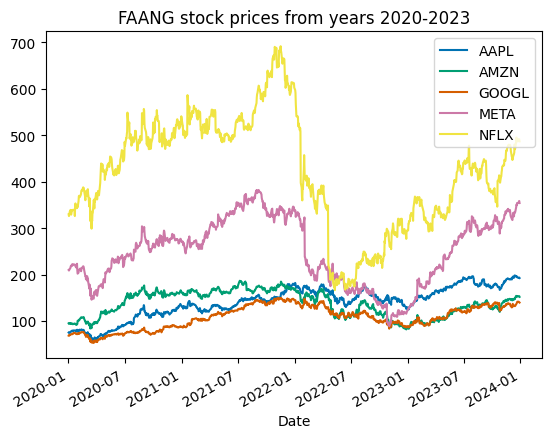

In [2]:
# Plotting the stock prices
stock_prices_df.plot(title="FAANG stock prices from years 2020-2023");

## 1. Benchmark: Portfólio Igualmente Ponderado (Equal-Weighted 1/N)

Calculamos o retorno esperado anualizado e a matriz de covariância amostral anualizada.
Em seguida, atribuímos peso igual (20% para cada uma das 5 ações FAANG) e avaliamos o Sharpe anualizado considerando taxa livre de risco ($R_f = 0\%$).


In [3]:
# 1. Matriz de Retornos Diários e Benchmark Igualmente Ponderado (1/N = 20% cada)
daily_returns = stock_prices_df.pct_change().dropna()
benchmark_returns = daily_returns.mean(axis=1)

# Retorno esperado anualizado (média diária x 252 dias úteis)
benchmark_exp_return = float(benchmark_returns.mean() * 252)

# Volatilidade anualizada do benchmark
benchmark_vol = float(benchmark_returns.std() * np.sqrt(252))

# Sharpe Ratio anualizado (taxa livre de risco Rf = 0%)
benchmark_sharpe_ratio = float(benchmark_exp_return / benchmark_vol)

# 2. Retornos Esperados e Matriz de Covariância para Otimização Média-Variância (MPT)
mu = expected_returns.mean_historical_return(stock_prices_df)
S = risk_models.sample_cov(stock_prices_df)

tickers = stock_prices_df.columns.tolist()
equal_weights = {ticker: 1.0 / len(tickers) for ticker in tickers}

print(f'[Benchmark] Retorno Esperado Anualizado: {benchmark_exp_return:.4f} ({benchmark_exp_return:.2%})')
print(f'[Benchmark] Volatilidade Anualizada:       {benchmark_vol:.4f} ({benchmark_vol:.2%})')
print(f'[Benchmark] Sharpe Ratio (Rf=0%):         {benchmark_sharpe_ratio:.4f}')


[Benchmark] Retorno Esperado Anualizado: 0.2360 (23.60%)
[Benchmark] Volatilidade Anualizada:       0.3269 (32.69%)
[Benchmark] Sharpe Ratio (Rf=0%):         0.7222


## 2. Portfólio de Mínima Volatilidade (Minimum Volatility)

Utilizando a Otimização Média-Variância de Markowitz, encontramos a combinação de pesos que minimiza o risco global (desvio-padrão) do portfólio.


In [ ]:
# Otimização para Mínima Volatilidade
ef_mv = EfficientFrontier(mu, S)
ef_mv.min_volatility()
mv_weights_dict = ef_mv.clean_weights()

# Salvar pesos como pandas Series com tickers como índice
mv_portfolio = pd.Series(mv_weights_dict)

# Salvar a volatilidade anualizada do portfólio como float
mv_perf = ef_mv.portfolio_performance(verbose=True, risk_free_rate=0.0)
mv_portfolio_vol = float(mv_perf[1])

print(f'\n[Min Volatility] Volatilidade: {mv_portfolio_vol:.2%}')
print('Pesos alocados:')
print((mv_portfolio * 100).round(2).astype(str) + '%')


## 3. Portfólio de Máximo Sharpe (Maximum Sharpe Ratio / Tangency)

Otimização para maximizar a inclinação da Capital Allocation Line (CAL), obtendo a maior relação retorno/risco com taxa livre de risco $R_f = 0\%$.


In [ ]:
# Otimização para Máximo Sharpe Ratio
ef_ms = EfficientFrontier(mu, S)
ef_ms.max_sharpe(risk_free_rate=0.0)
ms_weights_dict = ef_ms.clean_weights()

# Salvar pesos como pandas Series com tickers como índice
ms_portfolio = pd.Series(ms_weights_dict)

# Salvar o Sharpe anualizado como float
ms_perf = ef_ms.portfolio_performance(verbose=True, risk_free_rate=0.0)
ms_portfolio_sharpe = float(ms_perf[2])

print(f'\n[Max Sharpe] Sharpe Ratio: {ms_portfolio_sharpe:.4f}')
print('Pesos alocados:')
print((ms_portfolio * 100).round(2).astype(str) + '%')


## 4. Resumo Comparativo & Visualização da Fronteira Eficiente

Consolidação dos resultados dos três portfólios e visualização gráfica com simulação de Monte Carlo.


In [ ]:
# Tabela Resumo dos Portfólios
summary_df = pd.DataFrame({
    'Expected Return (p.a.)': [f'{benchmark_exp_return:.2%}', f'{mv_perf[0]:.2%}', f'{ms_perf[0]:.2%}'],
    'Volatility (p.a.)': [f'{benchmark_vol:.2%}', f'{mv_portfolio_vol:.2%}', f'{ms_perf[1]:.2%}'],
    'Sharpe Ratio (Rf=0%)': [f'{benchmark_sharpe_ratio:.4f}', f'{mv_perf[2]:.4f}', f'{ms_portfolio_sharpe:.4f}']
}, index=['Benchmark (1/N)', 'Minimum Volatility', 'Maximum Sharpe'])

weights_comparison_df = pd.DataFrame({
    'Benchmark (1/N)': pd.Series(equal_weights),
    'Min Volatility': mv_portfolio,
    'Max Sharpe': ms_portfolio
})

print('--- DESEMPENHO COMPARADO ---')
display(summary_df)
print('\n--- ALOCAÇÃO DE ATIVOS (%) ---')
display((weights_comparison_df * 100).round(2).astype(str) + '%')


In [ ]:
# Visualização Gráfica: Fronteira Eficiente (Monte Carlo) & Alocação de Pesos
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Monte Carlo
np.random.seed(42)
n_sim = 4000
sim_ret, sim_vol, sim_sr = [], [], []
for _ in range(n_sim):
    w = np.random.random(len(tickers))
    w /= np.sum(w)
    r = np.dot(w, mu)
    v = np.sqrt(np.dot(w.T, np.dot(S, w)))
    sim_ret.append(r)
    sim_vol.append(v)
    sim_sr.append(r / v)

sc = ax1.scatter(sim_vol, sim_ret, c=sim_sr, cmap='viridis', marker='o', s=10, alpha=0.35)
plt.colorbar(sc, ax=ax1, label='Sharpe Ratio (Rf=0%)')
ax1.scatter(benchmark_vol, benchmark_exp_return, color='royalblue', marker='s', s=140, label='Benchmark (1/N)', edgecolors='black')
ax1.scatter(mv_portfolio_vol, mv_perf[0], color='forestgreen', marker='^', s=160, label='Min Volatility', edgecolors='black')
ax1.scatter(ms_perf[1], ms_perf[0], color='crimson', marker='*', s=220, label='Max Sharpe', edgecolors='black')

for t in tickers:
    ax1.scatter(np.sqrt(S.loc[t, t]), mu[t], color='dimgray', s=50)
    ax1.annotate(t, (np.sqrt(S.loc[t, t]), mu[t]), xytext=(5, 3), textcoords='offset points', fontweight='bold')

ax1.set_title('Fronteira Eficiente & Portfólios Ótimos', fontsize=12, fontweight='bold')
ax1.set_xlabel('Volatilidade Anualizada')
ax1.set_ylabel('Retorno Esperado Anualizado')
ax1.legend(loc='upper left')

# Gráfico de Pesos
weights_comparison_df.plot(kind='bar', ax=ax2, width=0.8)
ax2.set_title('Comparação de Pesos por Estratégia', fontsize=12, fontweight='bold')
ax2.set_ylabel('Peso no Portfólio')
ax2.set_xticklabels(tickers, rotation=0, fontweight='bold')
ax2.legend(title='Estratégia')

plt.tight_layout()
plt.show()
